# TP N°3 : Filtrage Passe-Bas et Débruitage sous Python

**Objectifs :**
* Comprendre la notion de **fréquences spatiales** dans une image (basses fréquences = zones homogènes ; hautes fréquences = contours et bruit).
* Étudier la **réponse fréquentielle 2D** d'un noyau de convolution passe-bas .
* Implémenter le filtrage spatial par convolution/corrélation (`scipy.ndimage` / `skimage.filters`).
* Analyser l'influence de la **taille du noyau**, de la **normalisation des coefficients**, et comparer l'efficacité de différents filtres passe-bas (**Moyenneur, Gaussien, Médian, Passe-bas idéal/Butterworth**) face aux bruits **impulsionnel (poivre et sel)**, **gaussien** et **multiplicatif (speckle)**.

---

### 🛠️ 1. Configuration de l'environnement
Importer les bibliothèques nécessaires (`numpy`, `matplotlib`, `scipy.ndimage` et `skimage`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, median_filter, gaussian_filter
from skimage import data, color, util

# Chargement d'une image de test en niveaux de gris normalisée entre [0.0, 1.0]
I = data.camera().astype(np.float64) / 255.0

print(f"Image chargée : dimensions={I.shape}, type={I.dtype}, min={I.min():.2f}, max={I.max():.2f}")

Image chargée : dimensions=(512, 512), type=float64, min=0.00, max=1.00


---
## Partie 2 : Étude préliminaire — Réponse fréquentielle et filtrage de base

Sous MATLAB, la fonction `freqz2(h1, 32, 32)` calcule la transformée de Fourier 2D du noyau $h_1$ avec un rembourrage de zéros (*zero-padding*) sur une grille $32 \times 32$ et trace son module en 3D. Sous Python, nous réalisons exactement la même opération avec `np.fft.fft2(h1, s=(32, 32))` et `np.fft.fftshift()`.

Exécutez le programme ci-dessous :

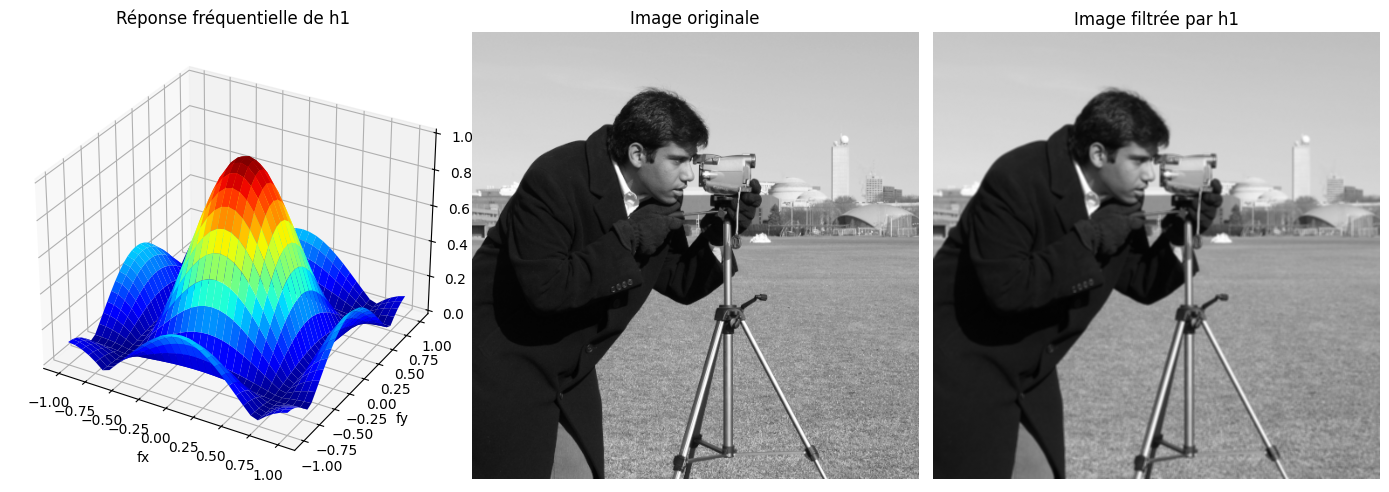

In [2]:
# 1. Création d'un filtre passe-bas moyenneur 3x3
h1 = np.ones((3, 3)) / 9.0

# 2. Calcul et affichage 3D de la réponse fréquentielle (équivalent de freqz2(h1, 32, 32))
H1_freq = np.abs(np.fft.fftshift(np.fft.fft2(h1, s=(32, 32))))
fx = np.linspace(-1, 1, 32)
fy = np.linspace(-1, 1, 32)
FX, FY = np.meshgrid(fx, fy)

fig = plt.figure(figsize=(14, 5))

# Sous-figure 1 : Réponse fréquentielle 3D
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
surf = ax1.plot_surface(FX, FY, H1_freq, cmap='jet')
ax1.set_title("Réponse fréquentielle de h1")
ax1.set_xlabel("fx")
ax1.set_ylabel("fy")

# 3. Filtrage de l'image I par h1 (équivalent de filter2(h1, I))
F = convolve(I, h1, mode='reflect')

# Sous-figure 2 : Image originale
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(I, cmap='gray', vmin=0, vmax=1)
ax2.set_title("Image originale")
ax2.axis('off')

# Sous-figure 3 : Image filtrée
ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(F, cmap='gray', vmin=0, vmax=1)
ax3.set_title("Image filtrée par h1")
ax3.axis('off')

plt.tight_layout()
plt.show()

**Questions 2 (Étude préliminaire) :**
1. Expliquez minutieusement chaque étape du programme ci-dessus, les fonctions utilisées (`np.ones`, `np.fft.fft2`, `np.fft.fftshift`, `convolve`) et leurs paramètres.
2. Comment justifiez-vous visuellement à partir de la courbe 3D que `h1` est bien un filtre **passe-bas** ?

**✍️ Vos réponses (Partie 2) :**
> *Double-cliquez ici pour rédiger vos explications...*

---
## Partie 3 : Étude pratique — Applications

### Question 3.1 : Ajout d'un bruit Poivre et Sel (*Salt & Pepper*) de densité 0.1
Sous Python, la fonction `util.random_noise(I, mode='s&p', amount=0.1)` (équivalent de `imnoise(I, 'salt & pepper', 0.1)` sous MATLAB) ajoute un bruit impulsionnel.
Appliquez ce bruit puis filtrez l'image bruitée avec `h1` ($3 \times 3$). Commentez le résultat.

In [ ]:
# À compléter :
I_sp = util.random_noise(I, mode='s&p', amount=0.1, rng=42)
# Filtrez I_sp avec h1 et affichez côte à côte I_sp et l'image filtrée


**✍️ Votre commentaire (Question 3.1) :**
> *Double-cliquez ici pour commenter l'efficacité du filtre moyenneur 3x3 sur le bruit poivre et sel...*

### Question 3.2 : Variation de l'ordre (taille) du filtre passe-bas
Augmentez la taille du filtre moyenneur en testant 5 filtres carrés d'ordre respectif **$3, 5, 7, 9$ et $11$** sur la même image bruitée `I_sp`. Commentez l'effet produit par chaque filtre et déduisez le compromis fondamental du filtrage passe-bas.

In [ ]:
ordres = [3, 5, 7, 9, 11]

# À compléter : Créez une boucle qui génère h = np.ones((k, k)) / (k**2),
# filtre I_sp et affiche les 5 résultats


**✍️ Vos commentaires et déductions (Question 3.2) :**
> *Double-cliquez ici pour rédiger votre analyse (atténuation du bruit vs perte de netteté/flou)...*

### Question 3.3 : Variation de la densité du bruit (de `0.05` à `0.9`)
Faites varier la densité `amount` du bruit *salt & pepper* (par exemple `[0.05, 0.2, 0.5, 0.7, 0.9]`), filtrez chaque image avec un filtre moyenneur (ex: $5 \times 5$) et commentez les résultats obtenus.

In [ ]:
densites = [0.05, 0.2, 0.5, 0.7, 0.9]

# À compléter :


**✍️ Votre commentaire (Question 3.3) :**
> *Double-cliquez ici pour rédiger votre commentaire...*

### Question 3.4 : Influence du type de bruit (Additif vs Multiplicatif) et de l'ordre du filtre
Testez les différents modèles de bruit disponibles dans `skimage.util.random_noise` :
* **Bruit additif Gaussien** : `mode='gaussian', var=0.02`
* **Bruit multiplicatif (Speckle / chatoiement)** : `mode='speckle', var=0.05`
* **Bruit de Poisson** : `mode='poisson'`
* **Bruit Impulsionnel (Poivre et Sel)** : `mode='s&p', amount=0.1`

Appliquez des filtres moyenneurs de différents ordres (ex: $3 \times 3$ et $7 \times 7$) sur chacun de ces bruits et décrivez leur comportement.

In [ ]:
# Génération des différents bruits
bruits = {
    "Gaussien (additif)": util.random_noise(I, mode='gaussian', var=0.02, rng=42),
    "Speckle (multiplicatif)": util.random_noise(I, mode='speckle', var=0.05, rng=42),
    "Poisson": util.random_noise(I, mode='poisson', rng=42),
    "Poivre & Sel": util.random_noise(I, mode='s&p', amount=0.1, rng=42)
}

# À compléter : Filtrez chaque image bruitée avec un filtre 3x3 et un filtre 7x7, puis affichez


**✍️ Votre analyse (Question 3.4) :**
> *Double-cliquez ici pour analyser l'effet du filtre moyenneur selon la nature statistique du bruit...*

### Question 3.5 : Influence du facteur de normalisation des coefficients du filtre
Modifiez les filtres passe-bas en changeant le dénominateur (la somme des coefficients n'est plus égale à $1$) :
* `np.ones((3,3)) / 5` et `np.ones((3,3)) / 15` (au lieu de `/ 9`)
* `np.ones((7,7)) / 25` et `np.ones((7,7)) / 75` (au lieu de `/ 49`)
* `np.ones((9,9)) / 60` et `np.ones((9,9)) / 110` (au lieu de `/ 81`)

Appliquez ces filtres sur l'image originale `I` (en veillant à fixer `vmin=0, vmax=1` dans `plt.imshow`) et expliquez mathématiquement le phénomène observé.

In [ ]:
filtres_non_norm = [
    ("3x3 / 5", np.ones((3, 3)) / 5.0),
    ("3x3 / 15", np.ones((3, 3)) / 15.0),
    ("7x7 / 25", np.ones((7, 7)) / 25.0),
    ("7x7 / 75", np.ones((7, 7)) / 75.0),
    ("9x9 / 60", np.ones((9, 9)) / 60.0),
    ("9x9 / 110", np.ones((9, 9)) / 110.0),
]

# À compléter : Appliquez chaque filtre sur I et affichez avec vmin=0, vmax=1


**✍️ Votre explication (Question 3.5) :**
> *Double-cliquez ici pour expliquer le rôle de la somme des coefficients du masque (gain statique / composante continue)...*

### Questions 3.6 & 3.7 : Comparaison des différents filtres passe-bas du cours
Programmez et comparez les principaux filtres passe-bas vus en cours sur l'image originale puis sur des images bruitées (Gaussien et Poivre & Sel) :
1. **Filtre Moyenneur** ($5 \times 5$)
2. **Filtre Gaussien** ($\sigma = 1.5$, via `gaussian_filter`)
3. **Filtre Médian** ($5 \times 5$, filtre non-linéaire via `median_filter`)
4. **Filtre Passe-Bas Idéal (ou Butterworth) dans le domaine fréquentiel** (coupure $D_0 = 40$)

*(Bonus quantitatif : vous pouvez utiliser `skimage.metrics.peak_signal_noise_ratio(I, I_filtree)` pour mesurer objectivement le PSNR en dB de chaque filtre !)*

In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr

def filtre_passe_bas_ideal(image, D0):
    M, N = image.shape
    F_shift = np.fft.fftshift(np.fft.fft2(image))
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    U, V = np.meshgrid(u, v, indexing='ij')
    D = np.sqrt(U**2 + V**2)
    H = (D <= D0).astype(float)
    return np.real(np.fft.ifft2(np.fft.ifftshift(F_shift * H)))

# À compléter : Comparez les 4 filtres sur I_gaussien et I_sp, et affichez les images + scores PSNR


**✍️ Étude comparative et conclusion (Questions 3.6 & 3.7) :**
> *Double-cliquez ici pour dresser le bilan comparatif de l'efficacité de chaque filtre selon le type de bruit et la préservation des contours (phénomène de Gibbs pour le filtre idéal, supériorité du médian sur le bruit impulsionnel, douceur du gaussien sur le bruit blanc gaussien)...*